In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
import pandas as pd
import numpy as np
import networkx as nx

In [4]:
DATA_ROOT_DIR = "../data/icefase/data"

In [5]:
metadata = pd.read_csv(f"{DATA_ROOT_DIR}/experiment_metadata.csv")
metadata

,Experiment id,Fate map id,Sample size,Sampling scheme
0,1,1,100,fixed
1,2,2,100,fixed
2,3,3,100,fixed
3,4,4,100,fixed
4,5,5,100,fixed
...,...,...,...,...
3305,3306,327,100,proportional
3306,3307,328,100,proportional
3307,3308,329,100,proportional
3308,3309,330,100,proportional


In [6]:
id = 0
eid = metadata.loc[id, "Experiment id"]
fatemap_id = metadata.loc[id, "Fate map id"]

print("id:\t\t", id)
print("experiment id:\t", eid)
print("fatemap id:\t", fatemap_id)


id:		 0
experiment id:	 1
fatemap id:	 1


In [7]:
import json

def get_fatemap(fatemap_id):

    with open(f"{DATA_ROOT_DIR}/fatemaps/fate_map{fatemap_id:04d}.json") as f:
        diff_T = nx.DiGraph()

        fatemap = json.load(f)

        all_nodes = fatemap["all_id"]
        for node in all_nodes:
            diff_T.add_node(node)
        
        merges = fatemap["merge"]
        for root, children in merges.items():
            for child in children:
                diff_T.add_edge(root, child)
        
        diff_times = fatemap["diff_time"]
        for node, time in diff_times.items():
            if time == "Inf": 
                diff_T.nodes[node]["diff_time"] = None
            else:
                diff_T.nodes[node]["diff_time"] = time
        
        diff_T.graph['root'] = fatemap["root_id"]
        
        transition_probs = pd.DataFrame(np.zeros((len(all_nodes), len(all_nodes))), index=all_nodes, columns=all_nodes)
        diff_mode_probs = fatemap["diff_mode_probs"]

        for root, children in merges.items():
            qs = diff_mode_probs[root]
            for children, q in zip(children, qs):
                transition_probs.loc[root, children] = q

    return diff_T, transition_probs

diff_T, transition_probs = get_fatemap(fatemap_id)

In [8]:
from plotters import plot_differentiation_tree

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


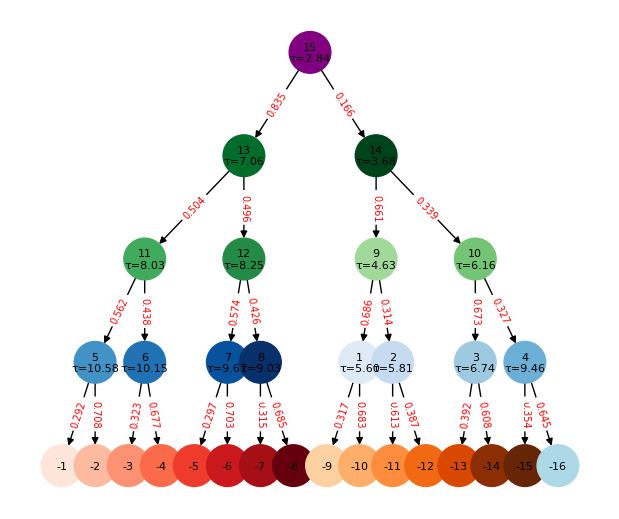

In [9]:
plot_differentiation_tree(diff_T, transition_probabilities=transition_probs)

In [10]:
import networkx as nx
from newick import read

tree = read(f"{DATA_ROOT_DIR}/simulated_phylogeny/{eid:04d}.newick")[0]

import networkx as nx
import re

def tree_to_nx(tree):
    G = nx.DiGraph()

    def node_name(n):
        return n.name if n.name else str(id(n))
    
    # parse cell_type from node name
    def parse_cell_type(name):
        # assumes format: type_<cell_type>_gen_...
        m = re.match(r"type_(-?\d+)_gen_(-?\d+)_(-?\d+)", name)
        if m:
            return str(m.group(1))
        else:
            return None

    root_name = node_name(tree)
    G.graph["root"] = root_name   # store root

    def add_node(node):
        parent = node_name(node)
        G.add_node(parent, state=parse_cell_type(parent))

        for child in node.descendants:
            child_name = node_name(child)

            G.add_edge(
                parent,
                child_name,
                weight=child.length,
            )

            add_node(child)

    add_node(tree)
    return G

T = tree_to_nx(tree)

In [11]:
T.nodes(data=True)

NodeDataView({'type_15_gen_0_1': {'state': '15'}, 'type_15_gen_1_1': {'state': '15'}, 'type_15_gen_2_1': {'state': '15'}, 'type_15_gen_3_1': {'state': '15'}, 'type_13_gen_-1_1': {'state': '13'}, 'type_13_gen_0_2': {'state': '13'}, 'type_13_gen_1_4': {'state': '13'}, 'type_13_gen_2_11': {'state': '13'}, 'type_13_gen_3_30': {'state': '13'}, 'type_-3_gen_2_1': {'state': '-3'}, 'type_13_gen_6_33': {'state': '13'}, 'type_-3_gen_2_43': {'state': '-3'}, 'type_-1_gen_1_48': {'state': '-1'}, 'type_-5_gen_3_2': {'state': '-5'}, 'type_-5_gen_3_1': {'state': '-5'}, 'type_13_gen_1_5': {'state': '13'}, 'type_13_gen_2_13': {'state': '13'}, 'type_13_gen_3_32': {'state': '13'}, 'type_13_gen_4_89': {'state': '13'}, 'type_-1_gen_1_19': {'state': '-1'}, 'type_-1_gen_1_20': {'state': '-1'}, 'type_13_gen_5_45': {'state': '13'}, 'type_13_gen_6_318': {'state': '13'}, 'type_-2_gen_1_69': {'state': '-2'}, 'type_-7_gen_6_55': {'state': '-7'}, 'type_-7_gen_6_24': {'state': '-7'}, 'type_13_gen_3_33': {'state': '13

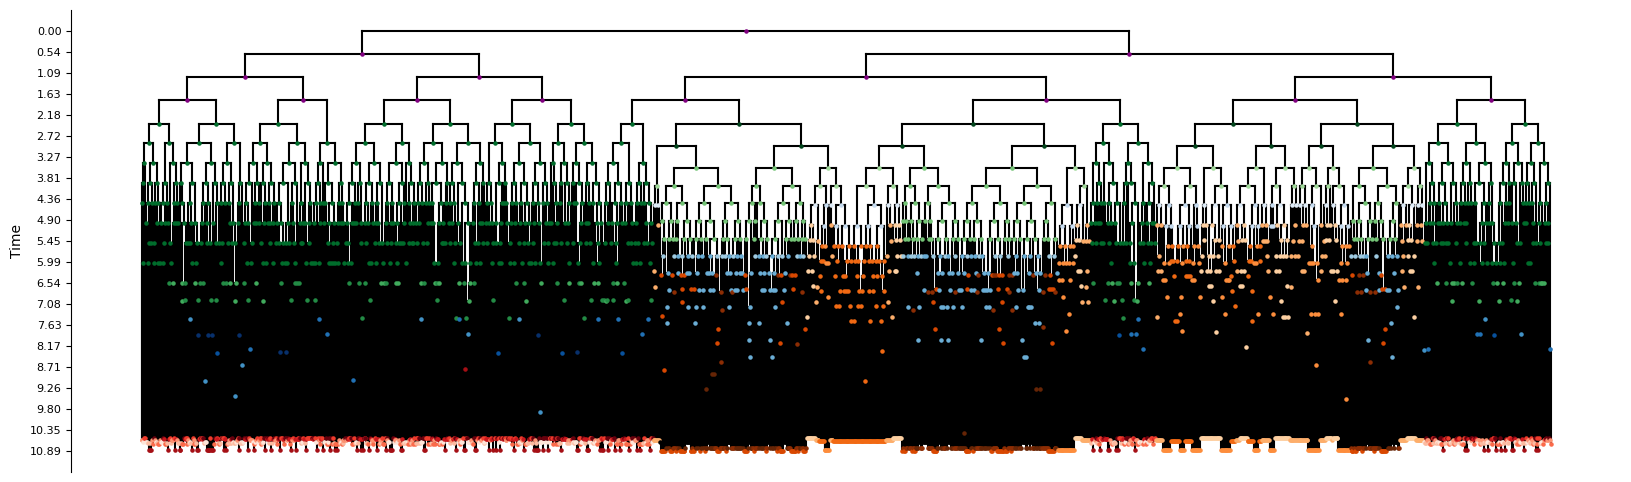

In [12]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph["root"], add_labels=False, figsize=(20, 6))

In [13]:
# nodes = [n for n, d in T.out_degree() if d == 0]

states = sorted(list(set(diff_T.nodes)))

for state in states:

    nodes = [n for n, d in T.nodes(data=True) if d.get("state") == state]
    distances = {}
    for node in nodes:
        distances[node] = nx.shortest_path_length(T, source=T.graph['root'], target=node, weight='weight')

    min_dist = min(distances.values())
    max_dist = max(distances.values())
    print(state, min_dist , max_dist )

-1 10.647010310199999 10.6470103116
-10 5.0367006205 10.6127595777


-11 5.5815018232 10.8563802444
-12 5.5815018232 10.628845636599998
-13 6.331970312599999 10.8929328348
-14 6.331970312699999 10.8195019554
-15 8.8839404096 10.8256670238
-16 8.8839404098 10.658903878799999
-2 10.6814081307 10.681408131800001
-3 10.6131174213 10.613117423
-4 10.7054676589 10.70546766
-5 10.5647756968 10.564775698399998
-6 10.5929452972 10.592945298500002
-7 8.7553501506 10.8560687925
-8 10.5630392753 10.563039276600001
-9 5.0367006205 10.568725710399999
1 4.511281589399999 4.5112815897
10 3.5493163516 5.3881236164
11 6.526780920199999 6.996499386600001
12 6.5267809202 7.4351253237999995
13 2.4 6.010933305700001
14 2.4 2.9746581758
15 0 1.7999999999999998
2 4.511281589399999 5.0463917065
3 5.8478254324 5.8478254326
4 5.8478254325 8.4502096987
5 7.466217851300001 9.8789802676
6 7.4662178512 9.052416539500001
7 7.8892975244 8.3444021774
8 7.8892975243 8.3223238377
9 3.5493163516 4.0302989708000005


In [14]:
from likelihood import add_node_times

In [15]:
T = add_node_times(T, T.graph['root'], reverse=False)

In [16]:
diff_T

In [17]:
diff_times = {}

for node in nx.dfs_postorder_nodes(diff_T, source=diff_T.graph['root']):
    if node[0] != "-": # internal node
        diff_time = 0

        children_states = list(diff_T.successors(node))

        nodes_with_children_state = [n for n, d in T.nodes(data=True) if d.get("state") in children_states]
        their_parent_nodes = list(set([list(T.predecessors(n))[0] for n in nodes_with_children_state]))
        
        for pnode in their_parent_nodes:
            children_nodes = list(T.successors(pnode))
            children_node_states = [T.nodes[child].get("state") for child in children_nodes]

            if len(set(children_node_states) & set(children_states)) > 1:
                diff_time = max(diff_time, T.nodes[pnode]['T'])

        diff_times[node] = diff_time


In [18]:
diff_times

{'5': 9.4768531988,
 '6': 8.2593171955,
 '11': 0,
 '7': 8.3444021774,
 '8': 8.3223238376,
 '12': 0,
 '13': 6.0109333055,
 '1': 4.511281589399999,
 '2': 5.0463917063,
 '9': 4.0302989705,
 '3': 5.8478254326,
 '4': 8.4502096987,
 '10': 5.3881236164,
 '14': 2.9746581758,
 '15': 1.7999999999999998}

In [19]:
EPS = 1e-9

for node in nx.dfs_preorder_nodes(diff_T, source=diff_T.graph['root']):
    if node[0] != "-":
        children_states = list(diff_T.successors(node))
        for child_state in children_states:
            if child_state[0] != "-":
                diff_times[child_state] = max(diff_times[child_state], diff_times[node]) + EPS

In [20]:
diff_times

{'5': 9.4768531998,
 '6': 8.2593171965,
 '11': 6.0109333075,
 '7': 8.3444021784,
 '8': 8.322323838600001,
 '12': 6.0109333075,
 '13': 6.0109333065,
 '1': 4.511281590399999,
 '2': 5.0463917073,
 '9': 4.0302989715,
 '3': 5.8478254336,
 '4': 8.4502096997,
 '10': 5.3881236174,
 '14': 2.9746581768,
 '15': 1.7999999999999998}

In [21]:
corrected_diff_T = diff_T.copy()

EPS = 1e-9

for state, diff_time in diff_times.items():
    corrected_diff_T.nodes[state]['diff_time'] = diff_time + EPS

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


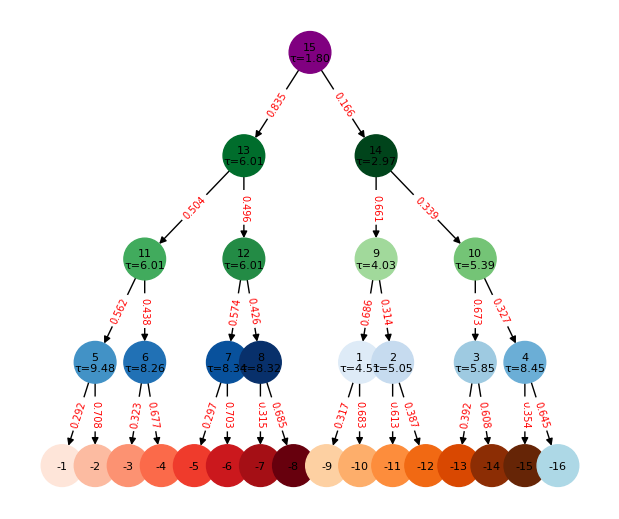

In [22]:
plot_differentiation_tree(corrected_diff_T, transition_probabilities=transition_probs)

In [31]:
rev_T = T.copy()

for n in T.nodes():
    rev_T.nodes[n]['T'] = (11.5 - T.nodes[n]['T']) / 11.5

In [41]:
rev_diff_T = corrected_diff_T.copy()
for n in corrected_diff_T.nodes():
    diff_time = rev_diff_T.nodes[n].get('diff_time')
    if diff_time is None: rev_diff_T.nodes[n]['diff_time'] = 0
    else: rev_diff_T.nodes[n]['diff_time'] = (11.5 - rev_diff_T.nodes[n]['diff_time']) / 11.5

In [42]:
types = list(diff_T.nodes())

transition_maps = [
    (i, succ)
    for i in diff_T.nodes()
    if (succ := list(diff_T.successors(i)))
]

print(types)
print(transition_maps)

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '-1', '-2', '-3', '-4', '-5', '-6', '-7', '-8', '-9', '-10', '-11', '-12', '-13', '-14', '-15', '-16']
[('1', ['-9', '-10']), ('2', ['-11', '-12']), ('3', ['-13', '-14']), ('4', ['-15', '-16']), ('5', ['-1', '-2']), ('6', ['-3', '-4']), ('7', ['-5', '-6']), ('8', ['-7', '-8']), ('9', ['1', '2']), ('10', ['3', '4']), ('11', ['5', '6']), ('12', ['7', '8']), ('13', ['11', '12']), ('14', ['9', '10']), ('15', ['13', '14'])]


In [43]:
trees = [rev_T]

In [49]:
import math
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

from likelihood import calculate_likelihood_of_tree, calculate_log_likelihood_of_tree


MAX_DEATH = 1.0
MAX_BIRTH = 10.0


def unpack_params(theta):

    k = 0

    # -------------------------
    # Death rates: (0, 1)
    # -------------------------
    death = {}
    for t in types:
        death[t] = MAX_DEATH * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Birth rates: (death, 10)
    # -------------------------
    birth = {}
    for t in types:
        birth[t] = death[t] + (MAX_BIRTH - death[t]) * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Transition matrix
    # -------------------------
    Q = pd.DataFrame(0.0, index=types, columns=types)

    for i, transition_to in transition_maps:

        logits = []
        js = []

        for j in transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1

        logits = np.array(logits)
        logits -= np.max(logits)

        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()

        for idx, j in enumerate(js):
            Q.loc[i, j] = probs[idx]

    return birth, death, Q


def neg_log_likelihood(theta, trees, diff_T, sampling_rate=1.0):

    birth, death, Q = unpack_params(theta)

    total_nll = 0.0

    for cell_lineage_T in trees:

        try:
            l, _, _ = calculate_likelihood_of_tree(
                birth_rates=birth,
                death_rates=death,
                sampling_rate=1.0,
                transition_probabilities=Q,
                cell_lineage_T=cell_lineage_T,
                diff_T=diff_T,
                root_time=1.0
            )
            if math.isnan(l):
                raise Exception("Gave nan output")
        except Exception:
            return 1e-300

        print(-l)

        total_nll += -np.log(l)

    return total_nll


def pack_initial():

    params = []

    # death parameters
    for t in types:
        params.append(0.0)

    # birth parameters
    for t in types:
        params.append(0.0)

    # transition logits
    for i, transition_to in transition_maps:
        for j in transition_to:
            params.append(0.0)

    return np.array(params)


def find_params(trees, diff_T):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, diff_T, 1.0),
        method="L-BFGS-B"
    )

    print(result)

    birth, death, Q = unpack_params(result.x)

    return birth, death, Q

In [50]:
birth_rates, death_rates, Q = find_params(trees, rev_diff_T)

-0.0
-0.0


/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_73491/2191193078.py:86: RuntimeWarning: divide by zero encountered in log
  total_nll += -np.log(l)
/Users/samin/workspace/phylodynamic-carta/.venv/lib/python3.13/site-packages/scipy/optimize/_numdiff.py:686: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]


-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
-0.0
  message: ABNORMAL: 
  success: False
   status: 2
      fun: 1e-300
        x: [ 0.000e+00  0.000e+00 ...  0.000e+00  0.000e+00]
      nit: 0
      jac: [       nan        nan ...        nan        nan]
     nfev: 1953
     njev: 21
 hess_inv: <92x92 LbfgsInvHessProduct with dtype=float64>


In [46]:
birth_rates, death_rates, Q

({'1': np.float64(5.25),
  '2': np.float64(5.25),
  '3': np.float64(5.25),
  '4': np.float64(5.25),
  '5': np.float64(5.25),
  '6': np.float64(5.25),
  '7': np.float64(5.25),
  '8': np.float64(5.25),
  '9': np.float64(5.25),
  '10': np.float64(5.25),
  '11': np.float64(5.25),
  '12': np.float64(5.25),
  '13': np.float64(5.25),
  '14': np.float64(5.25),
  '15': np.float64(5.25),
  '-1': np.float64(5.25),
  '-2': np.float64(5.25),
  '-3': np.float64(5.25),
  '-4': np.float64(5.25),
  '-5': np.float64(5.25),
  '-6': np.float64(5.25),
  '-7': np.float64(5.25),
  '-8': np.float64(5.25),
  '-9': np.float64(5.25),
  '-10': np.float64(5.25),
  '-11': np.float64(5.25),
  '-12': np.float64(5.25),
  '-13': np.float64(5.25),
  '-14': np.float64(5.25),
  '-15': np.float64(5.25),
  '-16': np.float64(5.25)},
 {'1': np.float64(0.5),
  '2': np.float64(0.5),
  '3': np.float64(0.5),
  '4': np.float64(0.5),
  '5': np.float64(0.5),
  '6': np.float64(0.5),
  '7': np.float64(0.5),
  '8': np.float64(0.5),
  '

In [48]:
from likelihood import calculate_likelihood_of_tree, calculate_log_likelihood_of_tree

likelihood, L, U = calculate_likelihood_of_tree(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rate=1.0,
    transition_probabilities=transition_probs,
    cell_lineage_T=rev_T,
    diff_T=rev_diff_T,
    root_time=1.0
)
likelihood

np.float64(0.0)

In [72]:
import json

d = L
d_str = {str(k): v for k, v in d.items()}

with open("../rough.txt", "w") as f:
    json.dump(d_str, f, indent=4)

In [32]:
from collections import defaultdict
import math

edge_ml = defaultdict(lambda : -np.inf)

for (u, v, t, s), val in L.items():
    edge_ml[(u, v)] = max(edge_ml[(u, v)], float(val))

zero_ml_edges = {e for e, v in edge_ml.items() if v == -np.inf or math.isnan(v)}

In [33]:
zero_ml_edges

{('type_15_gen_0_1', 'type_15_gen_1_1'),
 ('type_15_gen_0_1', 'type_15_gen_1_2'),
 ('type_15_gen_1_1', 'type_15_gen_2_1'),
 ('type_15_gen_1_1', 'type_15_gen_2_2'),
 ('type_15_gen_1_2', 'type_15_gen_2_3'),
 ('type_15_gen_1_2', 'type_15_gen_2_4'),
 ('type_15_gen_2_1', 'type_15_gen_3_1'),
 ('type_15_gen_2_1', 'type_15_gen_3_2'),
 ('type_15_gen_2_2', 'type_15_gen_3_3'),
 ('type_15_gen_2_2', 'type_15_gen_3_4'),
 ('type_15_gen_2_3', 'type_15_gen_3_5'),
 ('type_15_gen_2_3', 'type_15_gen_3_6'),
 ('type_15_gen_2_4', 'type_15_gen_3_7'),
 ('type_15_gen_2_4', 'type_15_gen_3_8'),
 ('type_5_gen_5_161', 'type_-1_gen_1_100'),
 ('type_5_gen_5_161', 'type_-1_gen_1_99'),
 ('type_6_gen_3_30', 'type_-4_gen_2_100'),
 ('type_6_gen_3_30', 'type_-4_gen_2_99')}

In [34]:
list(T.successors('type_15_gen_3_8'))

['type_13_gen_-1_11', 'type_13_gen_-1_12']

In [36]:
edge_ml[('type_15_gen_3_8', 'type_13_gen_-1_12')]

-243.4491829186721

In [257]:
zero_ml_edges

{('type_15_gen_0_1', 'type_15_gen_1_1'),
 ('type_15_gen_0_1', 'type_15_gen_1_2'),
 ('type_15_gen_1_1', 'type_15_gen_2_1'),
 ('type_15_gen_1_1', 'type_15_gen_2_2'),
 ('type_15_gen_1_2', 'type_15_gen_2_3'),
 ('type_15_gen_1_2', 'type_15_gen_2_4'),
 ('type_15_gen_2_1', 'type_15_gen_3_1'),
 ('type_15_gen_2_1', 'type_15_gen_3_2'),
 ('type_15_gen_2_2', 'type_15_gen_3_3'),
 ('type_15_gen_2_2', 'type_15_gen_3_4'),
 ('type_15_gen_2_3', 'type_15_gen_3_5'),
 ('type_15_gen_2_3', 'type_15_gen_3_6'),
 ('type_15_gen_2_4', 'type_15_gen_3_7'),
 ('type_15_gen_2_4', 'type_15_gen_3_8'),
 ('type_15_gen_3_1', 'type_13_gen_-1_1'),
 ('type_15_gen_3_1', 'type_13_gen_-1_2'),
 ('type_15_gen_3_2', 'type_13_gen_-1_3'),
 ('type_15_gen_3_3', 'type_13_gen_-1_5'),
 ('type_15_gen_3_3', 'type_13_gen_-1_6'),
 ('type_15_gen_3_4', 'type_13_gen_-1_7'),
 ('type_15_gen_3_4', 'type_13_gen_-1_8'),
 ('type_15_gen_3_5', 'type_13_gen_-1_9'),
 ('type_15_gen_3_5', 'type_14_gen_-1_1'),
 ('type_15_gen_3_6', 'type_13_gen_-1_10'),
 ('ty

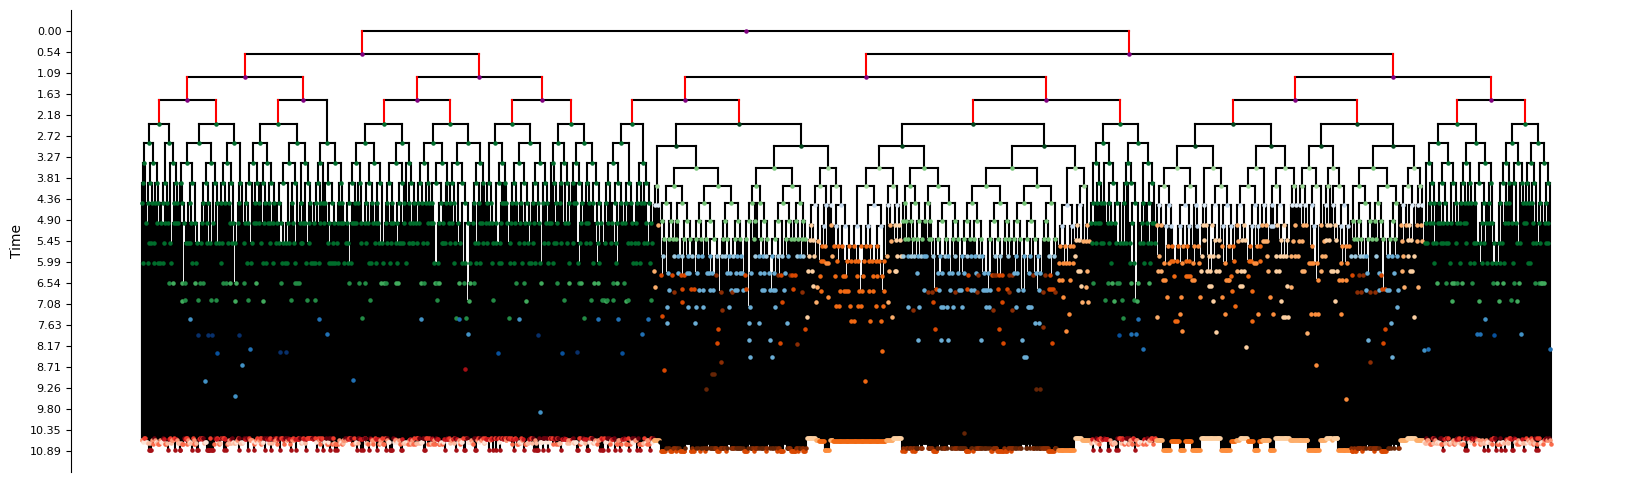

In [258]:
draw_ultrametric_tree(T, root=T.graph["root"], add_labels=False, figsize=(20, 6), red_edges=zero_ml_edges)